In [48]:
### Import Statements

import numpy as np
import math as m
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

In [49]:
### Define Matrix Dimensions and Size
n = 80
nt = 400
dt = 0.02

x_min = 1
x_max = 20

# Create an empty matrix
Z = np.zeros((nt,n))                       # Column Height
X = np.linspace(x_min, x_max, n)           # Column Position
V = np.zeros((nt,n))                       # Column Velocity
A = np.zeros((nt,n))                       # Column Acceleration
    


# Define the initial array
for i in range(len(Z[0])):
    Z[0][i] = (m.log(X[i]))



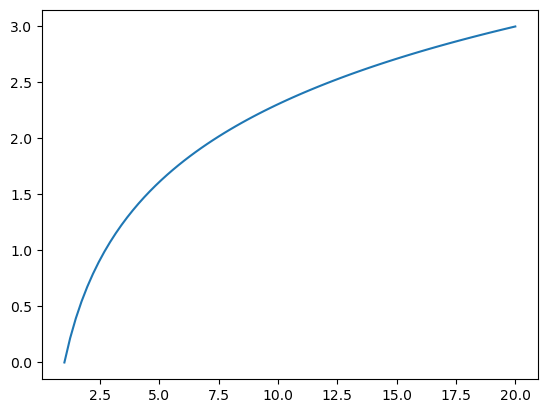

In [50]:
plt.plot(X, Z[0])

In [51]:
### Define Model Physics


for t in range(nt):
    S = np.zeros(n, dtype=float)
     
    for i in range(n):
        for j in range(n):
            if i != j:
                if X[j]-X[i] < 0:
                    S[i] += ((Z[t][j]-Z[t][i]) * -1) / (X[j]-X[i])
                else:
                    S[i] += (Z[t][j]-Z[t][i]) / (X[j]-X[i])
    
    for i in range(len(S)):
        if t+1 >= nt:
            break
        else:
            A[t+1][i] = S[i]

    #print(A)
    
    for i in range(len(S)):
        if t+1 >= nt:
            break
        else:
            V[t+1][i] = V[t][i] + (A[t+1][i] * dt)

    #print(V)
    
    for i in range(len(S)):
        if t+1 >= nt:
            break
        else:
            Z[t+1][i] = Z[t][i] + (V[t+1][i] * dt)

    #print(Z)



# first column seems to add up correctly (moving upward)
# second column is incorrectly stagnant.
# The third column is incorrectly moving downward. RESOLVED!!!!!

# The code has been fixed to produce the correct force numbers



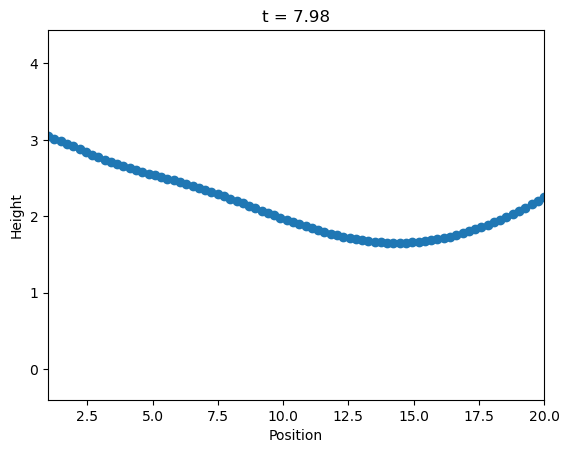

In [52]:
### Animate the frames

fig, ax = plt.subplots()
line, = ax.plot(X, Z[0], 'o-')            # 'o-' shows the individual columns

ax.set_xlim(x_min, x_max)
pad = 0.1 * (Z.max() - Z.min())
ax.set_ylim(Z.min() - pad, Z.max() + pad)  # fixed limits so the axes don't jump
ax.set_xlabel("Position")
ax.set_ylabel("Height")
title = ax.set_title("t = 0.00")

def update(frame):
    line.set_ydata(Z[frame])
    title.set_text(f"t = {frame * dt:.2f}")
    return line, title

ani = FuncAnimation(fig, update, frames=nt, interval=50, blit=False)
ani.save("IFWM_NatLog.gif", writer="pillow", fps=30)

plt.show()

In [53]:
array = np.zeros(nt, dtype=float)

for i in range(nt):
    array[i] = Z[i][int(n/2)]

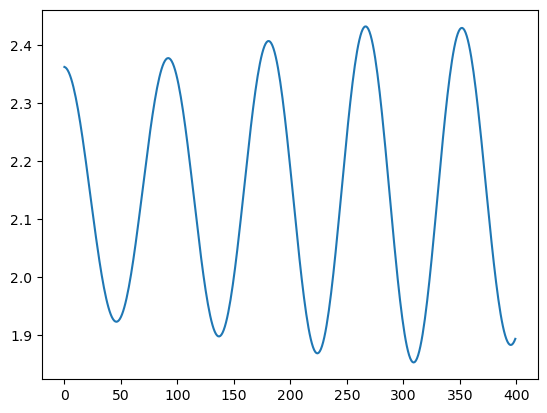

In [54]:
plt.plot(array)
